## Tutorial

https://colab.research.google.com/drive/13HLjC4myTvYcjLk2XBTZKbWJ2aqZUST1?usp=sharing#scrollTo=Fw4lw5hIVl9l

# Journal Citation metrics source
https://www.scimagojr.com/journalrank.php

In [29]:
import numpy as np
import pandas as pd
import textwrap

from tabulate import tabulate
from prettytable import PrettyTable
from pybibx.base import pbx_probe
import matplotlib.pyplot as plt

# Load data


In [30]:
BIB_FPATH = r'data/ncc_2026_06_01.bib'

DATABASE  = 'wos'

bibfile   = pbx_probe(file_bib = BIB_FPATH, db = DATABASE, del_duplicated = True)

A Total of 554 Documents were Found ( 555 Documents and 1 Duplicates )

Article = 484
Article in Press = 6
Article; Book Chapter = 3
Biographical-Item = 1
Correction = 7
Editorial Material = 8
Proceedings Paper = 10
Review = 35


# Clean data

In [31]:
# Health Analysis
health = bibfile.health_bib()

# Check Health
health

,Entries,Completeness (%),Number of Docs
0,Sources,98.38%,545
1,Abstracts,96.39%,534
2,Affiliation,99.64%,552
3,Author(s),100.00%,554
4,DOI,98.01%,543
5,Keywords - Authors,75.99%,421
6,Keywords - Plus,96.39%,534
7,References,0.00%,0
8,Year,100.00%,554


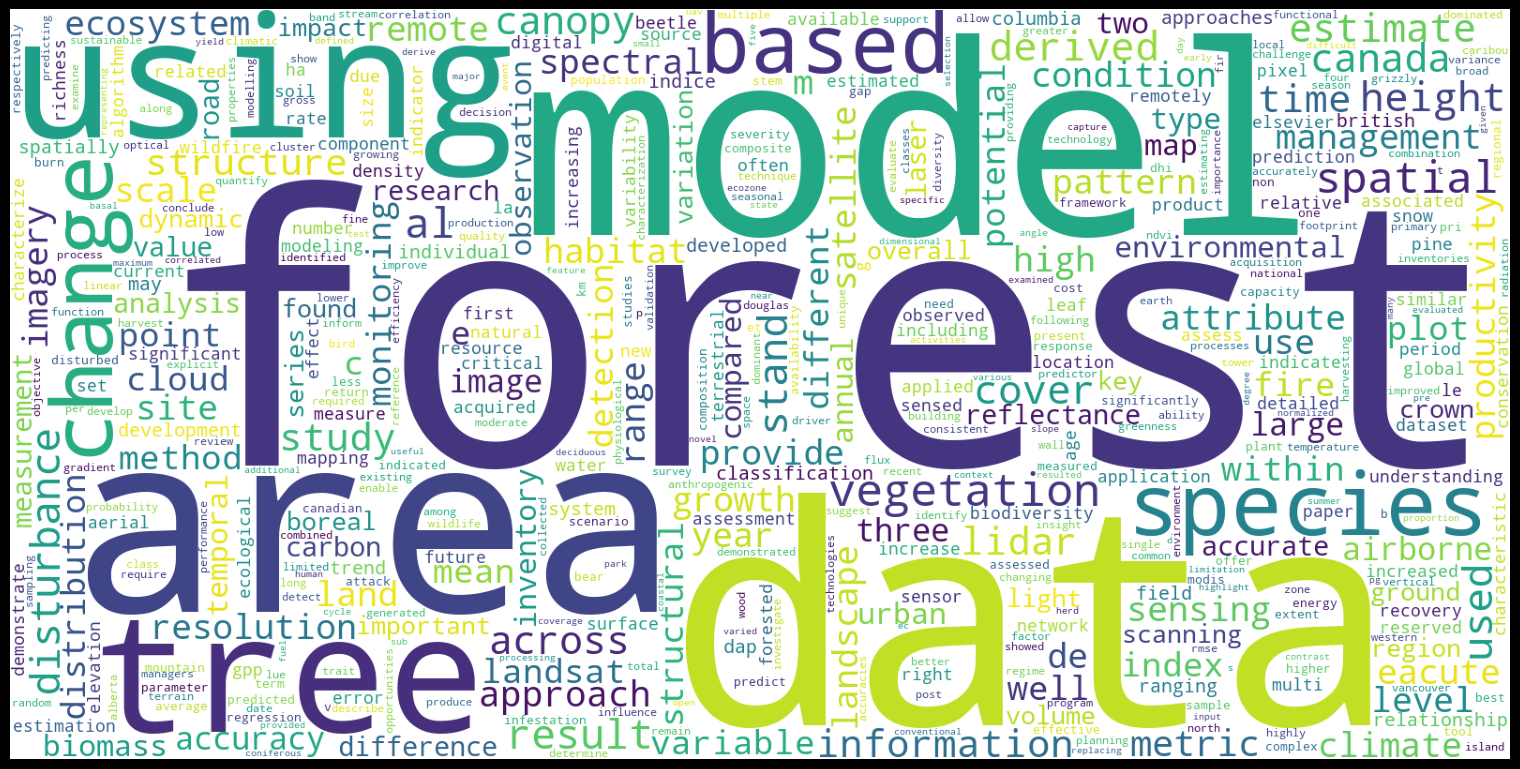

<Figure size 640x480 with 0 Axes>

In [32]:
# WordCloud from the Abstracts, Title, Authors Keywords or Keywords Plus
# Arguments: entry             = 'abs', 'title', 'kwa', or 'kwp'
#            rmv_custom_words  = A list of custom stopwords to clean the corpus;
bibfile.word_cloud_plot(entry = 'abs', size_x = 15, size_y = 10, wordsn = 500, rmv_custom_words = [])

plt.savefig('data/word_cloud.png', dpi=300, bbox_inches='tight')

In [33]:
bibfile.data.columns

Index(['abbrev_source_title', 'abstract', 'address', 'affiliation',
       'affiliation_', 'art_number', 'author', 'author_email',
       'author_keywords', 'book_author', 'book_group_author', 'booktitle',
       'chemicals_cas', 'coden', 'correspondence_address1', 'da',
       'doc_delivery_number', 'document_type', 'doi', 'earlyaccessdate',
       'editor', 'eissn', 'funding_acknowledgement', 'funding_details',
       'funding_text', 'funding_text 1', 'funding_text 2', 'funding_text 3',
       'isbn', 'issn', 'journal', 'keywords', 'language', 'month', 'note',
       'note_', 'number', 'number_of_cited_references', 'oa', 'orcid_numbers',
       'organization', 'page_count', 'pages', 'publisher', 'pubmed_id',
       'references', 'research_areas', 'researcherid_numbers', 'series',
       'source', 'sponsors', 'title', 'tradenames', 'unique_id', 'url',
       'usage_count_last_180_days', 'usage_count_since_2013', 'volume',
       'web_of_science_categories', 'web_of_science_index', 'ye

# Get articles df

In [34]:
article_t_cols = ['journal', 'year', 'author', 'title', 'document_type']

articles_df = bibfile.data[article_t_cols]

articles_df.to_csv('data/irss_articles.csv', index=False)

articles_df 

,journal,year,author,title,document_type
0,CANADIAN JOURNAL OF REMOTE SENSING,2026,"Boufford, Brianne L. and Coops, Nicholas C. an...",Understanding the Effect of Forest Recovery Pa...,Article
1,CANADIAN JOURNAL OF REMOTE SENSING,2026,"Brown, Madison S. and Coops, Nicholas C. and M...",Characterizing the Impact of Non-Stand Replaci...,Article
2,FORESTRY,2026,"Olson, Lukas G. and Coops, Nicholas C. and Mor...",The application of intra-canopy photogrammetry...,Article
3,FORESTRY,2026,"Seely, Harry and Coops, Nicholas C. and White,...",Addressing the small data problem in forestry:...,Article
4,REGIONAL ENVIRONMENTAL CHANGE,2026,"Mulverhill, Christopher and Coops, Nicholas C....",Climate-driven changes in tree species dominan...,Article
...,...,...,...,...,...
549,REMOTE SENSING OF ENVIRONMENT,2006,"Coops, Nicholas C. and Wulder, Michael A. and ...",Integrating remotely sensed and ancillary data...,Article
550,REMOTE SENSING OF ENVIRONMENT,2006,"Leuning, Ray and Hughes, Dale and Daniel, Paul...",A multi-angle spectrometer for automatic measu...,Article
551,REMOTE SENSING OF ENVIRONMENT,2006,"Goodwin, Nicholas R. and Coops, Nicholas C. an...",Assessment of forest structure with airborne L...,Article
552,REMOTE SENSING OF ENVIRONMENT,2006,"Coops, Nicholas C. and Johnson, Matt and Wulde...",Assessment of QuickBird high spatial resolutio...,Article


# Load citation metrics for all journals

In [35]:
citation_metrics_df = (pd.read_csv(r'data/journal_info.csv', delimiter=';')
                    .rename(columns={'Title': 'journal'})
)

citation_metrics_df.head(3)

,Rank,Sourceid,journal,Type,Issn,Publisher,Open Access,Open Access Diamond,SJR,SJR Best Quartile,...,Citations / Doc. (2years),Ref. / Doc.,%Female,Overton,Country,Region,Publisher.1,Coverage,Categories,Areas
0,1,28773,Ca-A Cancer Journal for Clinicians,journal,"15424863, 00079235",John Wiley and Sons Inc,No,No,"104,065",Q1,...,"285,55","90,23","46,34",2,United States,Northern America,John Wiley and Sons Inc,1950-2026,Hematology (Q1); Oncology (Q1),Medicine
1,2,20315,Nature Reviews Molecular Cell Biology,journal,"14710072, 14710080",Nature Research,No,No,"35,568",Q1,...,"45,22","98,42","34,87",0,United Kingdom,Western Europe,Nature Research,2000-2026,Cell Biology (Q1); Molecular Biology (Q1),"Biochemistry, Genetics and Molecular Biology"
2,3,29431,Quarterly Journal of Economics,journal,"00335533, 15314650",Oxford University Press,No,No,"33,069",Q1,...,"17,30","77,28","27,33",38,United Kingdom,Western Europe,Oxford University Press,1886-2026,Economics and Econometrics (Q1),"Economics, Econometrics and Finance"


# Aggregate articles by journal

In [36]:
# Fix first author name
articles_df['first_author'] = articles_df['author'].apply(lambda x: x.split('and')[0].strip() if isinstance(x, str) else x)
articles_df['first_author'] = articles_df['first_author'].apply(lambda x: f"{x.split(',')[1]} {x.split(',')[0]}" if len(x.split(',')) > 1 else x)

# Aggregate
journals_df = (articles_df.groupby('journal').agg({
    'year': 'max',
    'first_author': lambda x: x.value_counts().idxmin(),
    'title': lambda x: x.value_counts().idxmax(),
    'journal': 'count'
})
.rename(columns={'journal': 'n_irss_publications'})
.sort_values('n_irss_publications', ascending=False)
.reset_index()
)

journals_df.rename(columns={'first_author': 'recent_author'}, inplace=True)
journals_df.rename(columns={'title': 'recent_title'}, inplace=True)
journals_df.rename(columns={'year': 'recent_year'}, inplace=True)

# Ensure names are all uppercase for matching
journals_df['journal'] = journals_df['journal'].str.upper()
citation_metrics_df['journal'] = citation_metrics_df['journal'].str.upper()

# Fix "\&" substring replace with AND
journals_df['journal'] = journals_df['journal'].str.replace(r'\\&', 'AND', regex=True)

# Fix remote sensing issue
journals_df['journal'] = journals_df['journal'].str.replace('REMOTE   SENSING', 'REMOTE SENSING', regex=True)

# Fix TREES-STRUCTURE AND FUNCTION
journals_df['journal'] = journals_df['journal'].str.replace('TREES-STRUCTURE AND FUNCTION', 'TREES - STRUCTURE AND FUNCTION', regex=True)


# Join
journals_df = journals_df.merge(citation_metrics_df, on='journal', how='left')

#Check to see which are missing
missing_info = journals_df[journals_df['SJR'].isna()]
print("Journals missing SJR info:")
print(missing_info[['journal', 'n_irss_publications']])


Journals missing SJR info:
                                              journal  n_irss_publications
16                                            UNKNOWN                    9
36  PROGRESS IN PHYSICAL GEOGRAPHY-EARTH AND ENVIR...                    3
46             CANADIAN GEOGRAPHER-GEOGRAPHE CANADIEN                    2
49     JOURNAL OF GEOPHYSICAL RESEARCH-BIOGEOSCIENCES                    2
58  REMOTE SENSING APPLICATIONS-SOCIETY AND ENVIRO...                    2
64                IFOREST-BIOGEOSCIENCES AND FORESTRY                    2
81  CANADIAN JOURNAL OF FOREST RESEARCH-REVUE CANA...                    1
86     ENVIRONMENT AND PLANNING B-PLANNING AND DESIGN                    1
88            COMPUTERS ENVIRONMENT AND URBAN SYSTEMS                    1


In [41]:

journal_t_cols = ['journal', 'recent_year', 'recent_author', 'recent_title',
               'n_irss_publications', 
               'Open Access', 'SJR', 'SJR Best Quartile',
               'H index', 'Areas'
               ]

journals_df = journals_df[journal_t_cols]

journals_df.head(5)

,journal,recent_year,recent_author,recent_title,n_irss_publications,Open Access,SJR,SJR Best Quartile,H index,Areas
0,REMOTE SENSING OF ENVIRONMENT,2025,Samuel Grubinger,Seasonal vegetation dynamics for phenotyping u...,85,No,"4,266",Q1,397.0,Agricultural and Biological Sciences; Earth an...
1,CANADIAN JOURNAL OF REMOTE SENSING,2026,Brianne L. Boufford,Understanding the Effect of Forest Recovery Pa...,39,Yes,"0,560",Q2,90.0,Earth and Planetary Sciences
2,FOREST ECOLOGY AND MANAGEMENT,2024,Txomin Hermosilla,Characterizing long-term tree species dynamics...,27,No,"1,333",Q1,227.0,Agricultural and Biological Sciences; Environm...
3,INTERNATIONAL JOURNAL OF APPLIED EARTH OBSERVA...,2026,Lin Su,Individual sapling-level leaf chlorophyll cont...,24,Yes,"2,177",Q1,157.0,Earth and Planetary Sciences; Environmental Sc...
4,ECOLOGICAL INDICATORS,2026,Jose Riofrio,Linking species composition shifts from satell...,19,Yes,"2,099",Q1,222.0,Agricultural and Biological Sciences; Decision...


In [42]:
# Export
journals_df.to_csv('data/irss_journals_summary.csv', index=False)